# Titanic: EDA и разбор результатов

Предсказываем `Survived`, метрика accuracy. Сначала данные, потом результаты `python main.py`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from config import config
from data import CAT, NUM, add_features
from utils import make_model

sns.set_theme(style="whitegrid")

train_raw = pd.read_csv("data/train.csv")
test_raw = pd.read_csv("data/test.csv")
full = add_features(pd.concat([train_raw, test_raw], ignore_index=True))
train = full[: len(train_raw)].assign(Survived=train_raw["Survived"])
print(train_raw.shape, test_raw.shape)
train_raw.head()

(891, 12) (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Пропуски

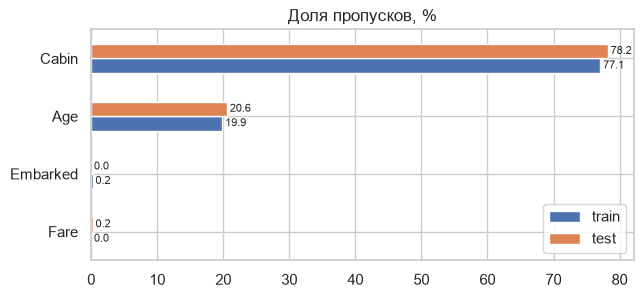

In [2]:
missing = pd.DataFrame({"train": train_raw.isna().mean(), "test": test_raw.isna().mean()})
missing = missing[missing.sum(axis=1) > 0].sort_values("train")
ax = (missing * 100).plot.barh(figsize=(7, 3), title="Доля пропусков, %")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=8, padding=2)
plt.show()

- `Cabin` пустой у 77%: берём из него только палубу и флаг `HasCabin`.
- `Age` пустой у 20%: заполняем медианой по `Title` (у `Master` 3.5 года, у `Mr` 30).
- `Embarked` и `Fare`: пара пропусков, мода и медиана.

## Таргет и категориальные признаки

Выжило: 38.4%


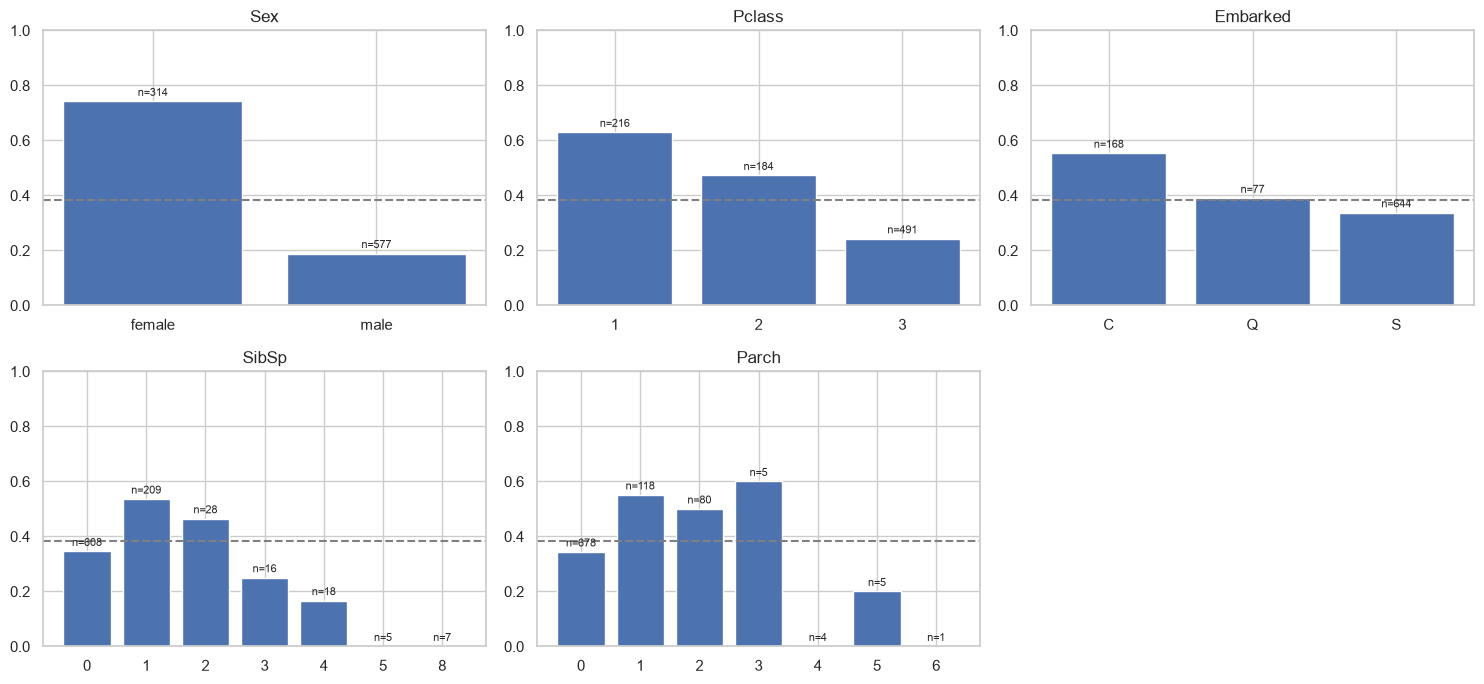

In [3]:
def survival_bars(df, cols):
    """Доля выживших по значениям каждого признака, пунктир - средняя по выборке."""
    fig, axes = plt.subplots(2, 3, figsize=(15, 7))
    for ax, col in zip(axes.ravel(), cols):
        stats = df.groupby(col)["Survived"].agg(["mean", "size"])
        ax.bar(stats.index.astype(str), stats["mean"])
        ax.axhline(df["Survived"].mean(), color="gray", ls="--")
        ax.set(title=col, ylim=(0, 1))
        for i, (rate, n) in enumerate(zip(stats["mean"], stats["size"])):
            ax.text(i, rate + 0.02, f"n={n}", ha="center", fontsize=8)
    for ax in axes.ravel()[len(cols):]:
        ax.remove()
    plt.tight_layout()
    plt.show()


print(f"Выжило: {train['Survived'].mean():.1%}")
survival_bars(train, ["Sex", "Pclass", "Embarked", "SibSp", "Parch"])

- Выжило 38%, поэтому фолды стратифицированные.
- Пол решает больше всего: выжили 74% женщин и 19% мужчин.
- Класс тоже: 63%, 47% и 24%.
- Одиночки и большие семьи выживали хуже маленьких семей, отсюда `FamilySize` и `FamilyGroup`.

## Числовые признаки и выбросы

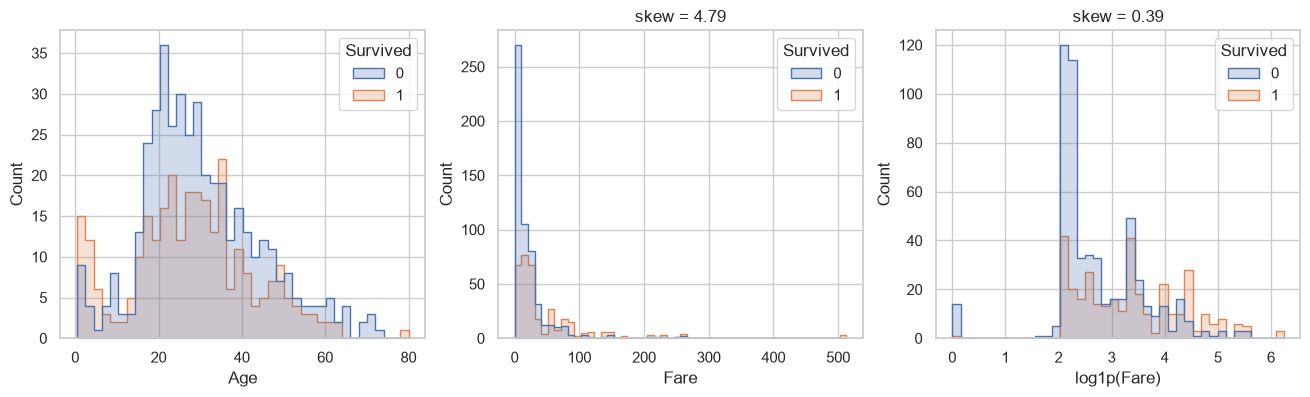

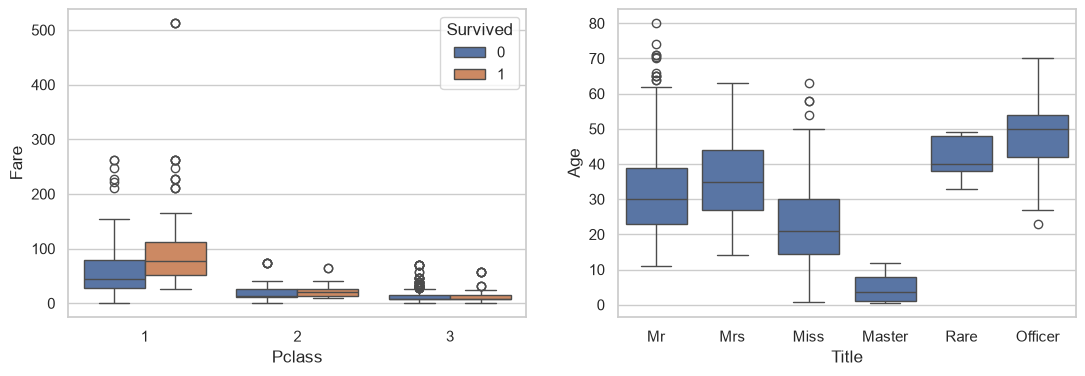

Выживаемость по возрасту:
Age
(0, 12]     0.58
(12, 18]    0.43
(18, 30]    0.36
(30, 50]    0.42
(50, 80]    0.34
Name: Survived, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=train, x="Age", hue="Survived", bins=40, element="step", ax=axes[0])
sns.histplot(data=train, x="Fare", hue="Survived", bins=50, element="step", ax=axes[1])
sns.histplot(x=np.log1p(train["Fare"]), hue=train["Survived"], bins=40, element="step", ax=axes[2])
axes[1].set_title(f"skew = {train['Fare'].skew():.2f}")
axes[2].set(title=f"skew = {np.log1p(train['Fare']).skew():.2f}", xlabel="log1p(Fare)")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=train, x="Pclass", y="Fare", hue="Survived", ax=axes[0])
sns.boxplot(data=train, x="Title", y="Age", ax=axes[1])
plt.show()
print("Выживаемость по возрасту:")
print(train.groupby(pd.cut(train["Age"], [0, 12, 18, 30, 50, 80]), observed=True)["Survived"].mean().round(2))

- Дети до 12 лет выживали чаще (58%), выбросов в `Age` нет.
- `Fare` сильно скошен (skew 4.8), но дорогие билеты настоящие, не удаляем. Для KNN и линейных моделей берём логарифм.

## Новые признаки

- `Title` - обращение из имени
- `FamilySize`, `IsAlone`, `FamilyGroup` - размер семьи
- `Deck`, `HasCabin` - палуба и есть ли каюта
- `TicketFreq`, `FarePerPerson` - сколько людей на билете и цена на человека
- `AgeMissing` - возраст был пропущен
- `SexPclass` - пол и класс вместе

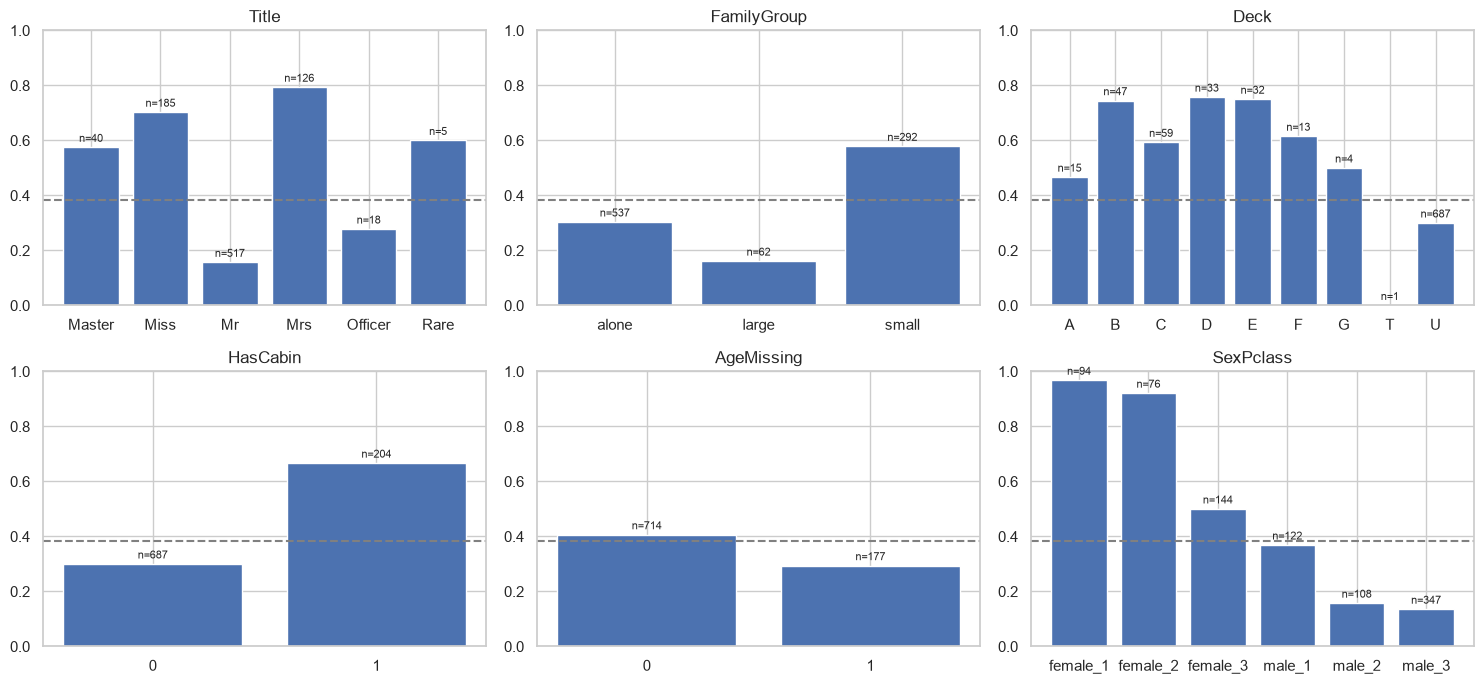

In [5]:
survival_bars(train, ["Title", "FamilyGroup", "Deck", "HasCabin", "AgeMissing", "SexPclass"])

- `Title` разделяет мужчин: мальчики выжили в 57% случаев, взрослые в 16%.
- Женщины 1 и 2 класса выжили почти все, в 3 классе половина. Поэтому добавили `SexPclass`.

## Корреляции и константные признаки

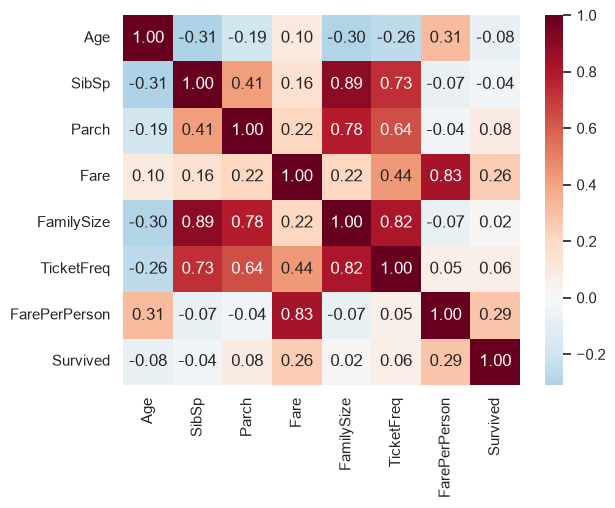

Доля самого частого значения: {'AgeMissing': 0.8, 'HasCabin': 0.77, 'Deck': 0.77}


In [6]:
sns.heatmap(train[NUM + ["Survived"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.show()

top_share = train[NUM + CAT].apply(lambda col: col.value_counts(normalize=True).iloc[0])
print("Доля самого частого значения:", top_share.sort_values(ascending=False).head(3).round(2).to_dict())

- Константных признаков нет.
- Сильно скоррелированы только признаки, сделанные друг из друга (`SibSp` и `FamilySize` 0.89). Удаление проверим в абляции.

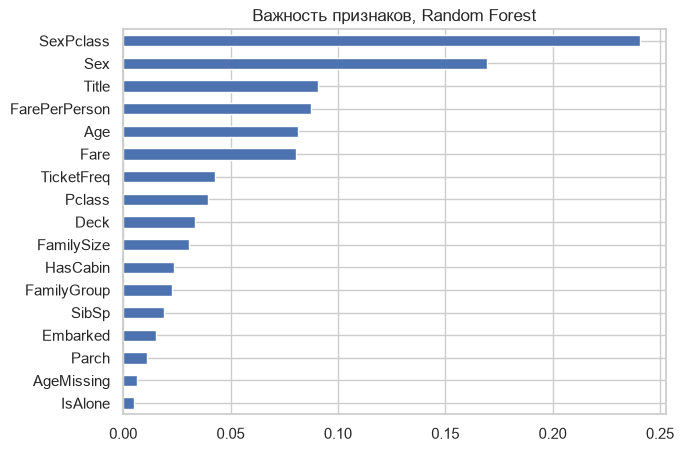

In [7]:
prep = {"encoding": "ordinal", "scale": False}
rf = make_model(config, "random_forest", {"n_estimators": 500, "max_depth": 7}, prep)
rf.fit(train, train["Survived"])
pd.Series(rf[-1].feature_importances_, index=NUM + CAT).sort_values().plot.barh(
    figsize=(7, 5), title="Важность признаков, Random Forest")
plt.show()

Важнее всего `SexPclass`, `Sex` и `Title`. Почти не нужны `IsAlone`, `AgeMissing`, `Parch` и `Embarked`.

## Результаты моделей

Accuracy на StratifiedKFold(5).

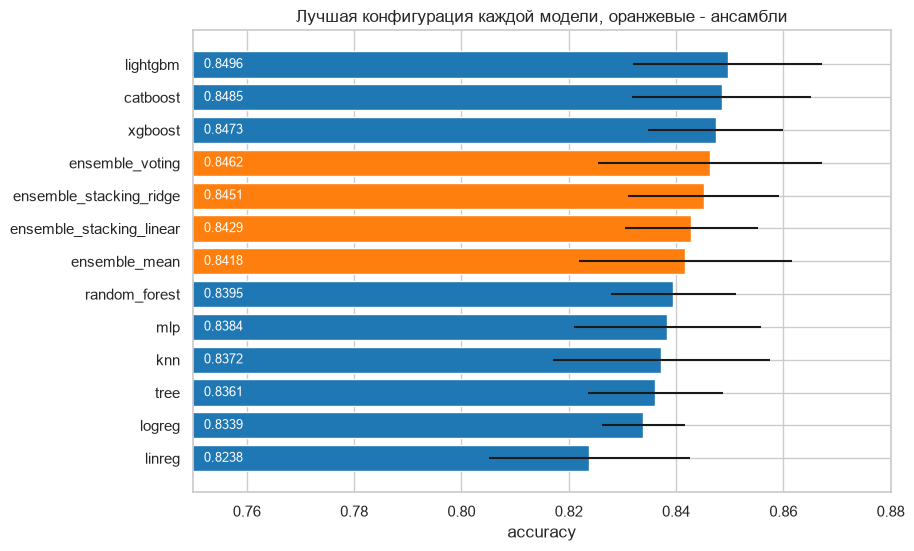

,name,accuracy,std,roc_auc
94,"lightgbm[learning_rate=0.02,num_leaves=15,min_...",0.8496,0.0176,0.8855
78,"catboost[depth=4,learning_rate=0.03,l2_leaf_re...",0.8485,0.0167,0.8814
142,"xgboost[max_depth=3,learning_rate=0.1,subsampl...",0.8473,0.0127,0.8841
215,ensemble_voting,0.8462,0.0209,0.8710
217,ensemble_stacking_ridge,0.8451,0.0141,0.8851
216,ensemble_stacking_linear,0.8429,0.0124,0.8861
214,ensemble_mean,0.8418,0.0199,0.8841
75,"random_forest[max_depth=7,min_samples_leaf=3,m...",0.8395,0.0117,0.8772
183,"mlp[n_layers=1,batchnorm=False,dropout=0,lr=0.01]",0.8384,0.0174,0.8675
34,"knn[n_neighbors=15,weights=uniform,metric=eucl...",0.8372,0.0202,0.8755


In [8]:
results = pd.read_csv("outputs/results.csv")
best = (results[results["stage"].isin(["grid", "ensemble"])]
        .sort_values("accuracy", ascending=False, kind="stable").drop_duplicates("model"))

fig, ax = plt.subplots(figsize=(9, 6))
colors = np.where(best["stage"] == "ensemble", "tab:orange", "tab:blue")
ax.barh(best["model"], best["accuracy"], xerr=best["std"], color=colors)
ax.invert_yaxis()
ax.set(xlim=(0.75, 0.88), xlabel="accuracy", title="Лучшая конфигурация каждой модели, оранжевые - ансамбли")
for y, acc in enumerate(best["accuracy"]):
    ax.text(0.752, y, f"{acc:.4f}", va="center", color="white", fontsize=9)
plt.show()
best[["name", "accuracy", "std", "roc_auc"]].round(4)

- Бейзлайн (линейная регрессия) 0.824, лучший LightGBM 0.850.
- Std по фолдам около 0.015, разница меньше 0.01 - шум.
- Нейросеть 0.838, на уровне леса и KNN.
- Ансамбли LightGBM не обогнали, лучший из них (голосование) 0.846.

## Абляция препроцессинга

Логрег и LightGBM с лучшими параметрами, меняем по одному шагу препроцессинга.

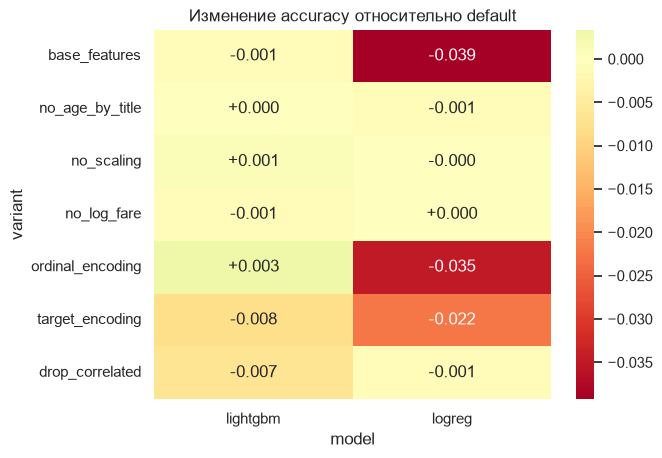

model,lightgbm,logreg
variant,,
default,0.8451,0.8339
base_features,0.8440,0.7946
no_age_by_title,0.8451,0.8328
no_scaling,0.8462,0.8339
no_log_fare,0.8440,0.8339
ordinal_encoding,0.8485,0.7991
target_encoding,0.8373,0.8115
drop_correlated,0.8384,0.8328


In [9]:
ablation = results[results["stage"] == "ablation"].copy()
ablation["variant"] = ablation["name"].str.split(":").str[1]
table = ablation.pivot(index="variant", columns="model", values="accuracy").loc[ablation["variant"].unique()]
sns.heatmap(table.drop("default") - table.loc["default"], annot=True, fmt="+.3f", cmap="RdYlGn", center=0)
plt.title("Изменение accuracy относительно default")
plt.show()
table.round(4)

- Логрегу новые признаки дают +3.9 п.п., one-hot лучше ordinal на 3.5 п.п.
- LightGBM заметно теряет только от target encoding (-0.8 п.п.) и удаления `Fare` и `FamilySize` (-0.7 п.п.).
- Скейлинг, логарифм и `Age` по `Title` в пределах шума.

## Гиперпараметры

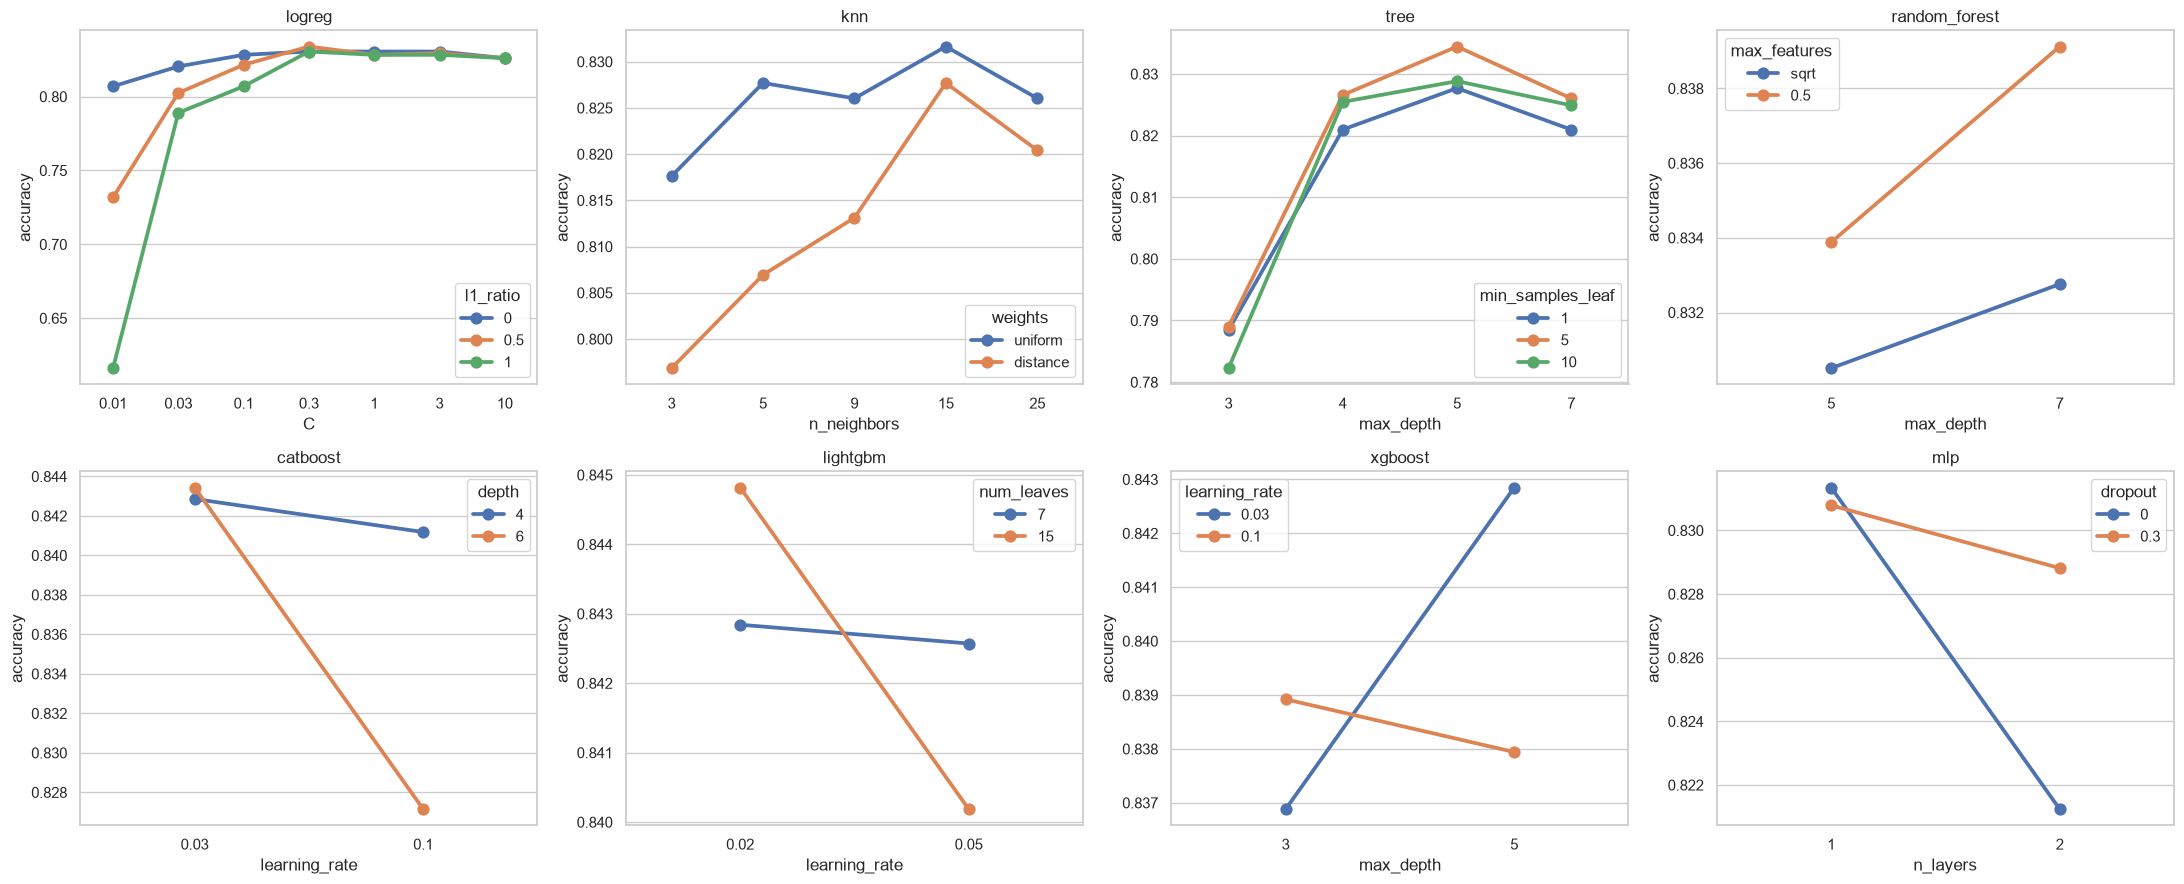

In [10]:
def param_plot(ax, models, param, hue=None):
    """Средняя accuracy по значениям параметра (усреднение по остальным параметрам сетки)."""
    df = results[(results["stage"] == "grid") & results["model"].isin(models)].copy()
    for col in filter(None, [param, hue]):
        df[col] = [str(json.loads(p)[col]) for p in df["params"]]
    sns.pointplot(data=df, x=param, y="accuracy", hue=hue or "model", errorbar=None, ax=ax)
    ax.set_title(", ".join(models))


fig, axes = plt.subplots(2, 4, figsize=(22, 9))
param_plot(axes[0, 0], ["logreg"], "C", "l1_ratio")
param_plot(axes[0, 1], ["knn"], "n_neighbors", "weights")
param_plot(axes[0, 2], ["tree"], "max_depth", "min_samples_leaf")
param_plot(axes[0, 3], ["random_forest"], "max_depth", "max_features")
param_plot(axes[1, 0], ["catboost"], "learning_rate", "depth")
param_plot(axes[1, 1], ["lightgbm"], "learning_rate", "num_leaves")
param_plot(axes[1, 2], ["xgboost"], "max_depth", "learning_rate")
param_plot(axes[1, 3], ["mlp"], "n_layers", "dropout")
plt.tight_layout()
plt.show()

- Логрег: лучше C от 0.3 до 3, при C=0.01 L1 обнуляет все веса (0.616).
- KNN: лучше k=15 и `uniform`.
- Дерево: лучше `max_depth=5`, на 3 недообучается.
- Random Forest: лучше `max_features=0.5` и глубина 7.
- CatBoost: лучше learning rate 0.03 и `depth=4`.
- Нейросеть: одного слоя хватает, dropout 0.3 немного помогает, BatchNorm ничего не меняет.

## Почему ансамбль почти не помогает

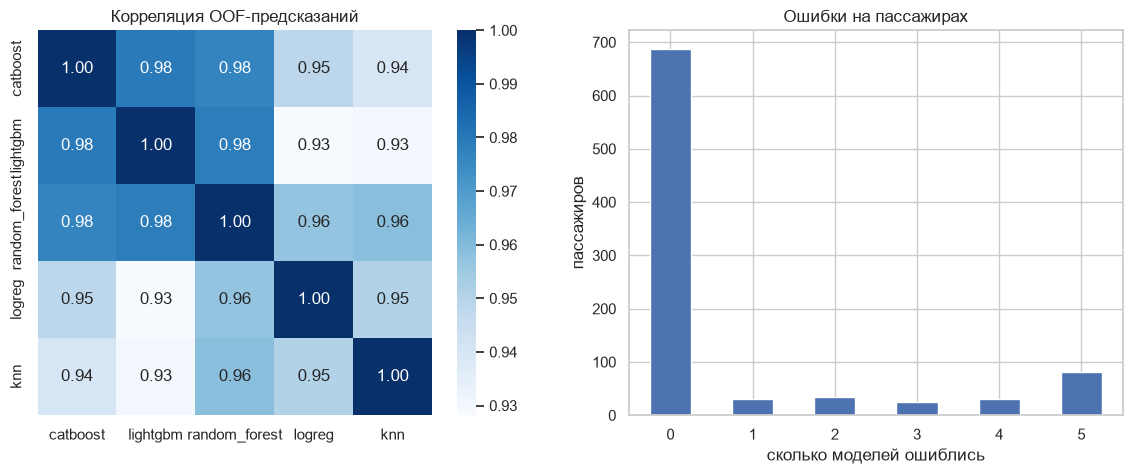

Все модели ошибаются на 9.1% пассажиров, хотя бы одна на 22.8%


Sex     Survived
female  0           21
        1            4
male    0            1
        1           55
dtype: int64

In [11]:
oof = pd.read_csv("outputs/oof.csv")[list(config.ensemble.models)]
wrong = (oof >= 0.5).astype(int).ne(train["Survived"], axis=0)
n_wrong = wrong.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(oof.corr(), annot=True, fmt=".2f", cmap="Blues", ax=axes[0])
axes[0].set_title("Корреляция OOF-предсказаний")
n_wrong.value_counts().sort_index().plot.bar(ax=axes[1], rot=0, xlabel="сколько моделей ошиблись",
                                             ylabel="пассажиров", title="Ошибки на пассажирах")
plt.show()
print(f"Все модели ошибаются на {(n_wrong == oof.shape[1]).mean():.1%} пассажиров, "
      f"хотя бы одна на {(n_wrong > 0).mean():.1%}")
train[n_wrong == oof.shape[1]].groupby(["Sex", "Survived"]).size()

Модели скоррелированы на 0.93-0.98, а на 9.1% пассажиров ошибаются все сразу. Исправлять ансамблю почти нечего.

## Один фолд против пяти

In [12]:
top = results[results["stage"] == "holdout"]["model"].iloc[0]
results[results["model"].eq(top) & results["stage"].isin(["grid", "holdout"])].sort_values(
    "accuracy", ascending=False).drop_duplicates("stage")[["stage", "name", "accuracy", "std", "roc_auc"]].round(4)

,stage,name,accuracy,std,roc_auc
94,grid,"lightgbm[learning_rate=0.02,num_leaves=15,min_...",0.8496,0.0176,0.8855
218,holdout,lightgbm (1 fold),0.8101,0.0000,0.8412


Один сплит 0.810, пять фолдов 0.850. В валидации одного сплита 179 пассажиров, одна ошибка там стоит 0.6 п.п.,
так что одному сплиту верить нельзя.

## Итог

- Главное в данных: пол, класс и обращение.
- Лучшая модель LightGBM (0.850), ансамбли её не обогнали.
- Нейросеть (0.838) не лучше классических моделей.
- Новые признаки нужны линейным моделям, деревьям почти нет.
- Разница меньше 0.01 - шум, одному сплиту не верим.